# Ciencia de Datos en Acción: análisis y predicción de salarios

**Proyecto final | Ingeniería de Sistemas | Equipo: [Integrante 1], [Integrante 2], [Integrante 3 opcional]**

**Pregunta:** ¿Cómo se distribuyen los salarios en una organización simulada y qué tan bien podemos predecirlos a partir de variables laborales?

> **Transparencia:** estos datos se generaron artificialmente, con semilla fija. No son nóminas reales de Colombia, de SAP ni de IBM. El objetivo es practicar el flujo de ciencia de datos, no realizar afirmaciones causales ni decisiones salariales reales.

**Mapa del trabajo:** Etapa 1 (carga, calidad, limpieza) → Etapa 2 (descripción e hipótesis) → Etapa 3 (storytelling, entrenamiento, evaluación y caso profesional).

## Cómo ejecutar

1. Descarga y descomprime la carpeta completa del proyecto o clona tu repositorio de GitHub.
2. Abre este archivo en Colab. Si Colab no encuentra `datos/empleados_original.csv`, carga manualmente ese CSV cuando el cuaderno lo solicite.
3. Ejecuta **Entorno de ejecución → Ejecutar todas**. Los resultados y gráficas se guardan en `resultados/` cuando se ejecuta desde el directorio del proyecto.

**Dependencias:** `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`.

In [1]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, cross_validate, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.figsize":(9,5),"figure.dpi":120,"axes.spines.top":False,"axes.spines.right":False})
pd.set_option("display.max_columns", 25)

# Descubrimiento del CSV: compatible con la raíz del repo y Colab.
candidatos = [Path.cwd(), Path.cwd().parent, Path('/content/proyecto_ciencia_datos_salarios'), Path('/content')]
ruta = next((p/'datos'/'empleados_original.csv' for p in candidatos if (p/'datos'/'empleados_original.csv').exists()), None)
if ruta is None:
    try:
        from google.colab import files
        print('Carga ahora empleados_original.csv del ZIP del proyecto:')
        subidos = files.upload()
        if 'empleados_original.csv' not in subidos:
            raise FileNotFoundError('Se necesita empleados_original.csv')
        ruta = Path('empleados_original.csv')
    except ImportError as exc:
        raise FileNotFoundError('No se encuentra datos/empleados_original.csv. Ejecuta el notebook desde la carpeta del proyecto.') from exc
ROOT = ruta.parent.parent if ruta.parent.name=='datos' else Path.cwd()
OUT=ROOT/'resultados'; GRAF=OUT/'graficos'
GRAF.mkdir(parents=True,exist_ok=True)
print('Dataset:',ruta.resolve(), '| Salida:',OUT.resolve())

Dataset: /mnt/data/proyecto_ciencia_datos_salarios/datos/empleados_original.csv | Salida: /mnt/data/proyecto_ciencia_datos_salarios/resultados


# ETAPA 1 · Fundamentos, exploración y limpieza

## 1. Contexto, unidad de análisis y variables
Cada fila representa un **empleado ficticio** y cada columna una característica laboral o demográfica. `SalarioMensualCOP` es nuestra variable objetivo expresada en pesos colombianos simulados.

El dataset tiene 12 columnas: ID, edad, departamento, nivel de cargo, experiencia, antigüedad, educación, ciudad, modalidad, horas extra, satisfacción y salario. Las variables categóricas son nominales u ordinales; otras son cuantitativas discretas o continuas.

**Preguntas guía:** ¿cuánto varían los salarios?, ¿cómo cambian por nivel y departamento?, ¿puede una regresión lineal predecir el salario mejor que adivinar el valor mediano?

In [2]:
df_raw = pd.read_csv(ruta,encoding='utf-8-sig')
print('Dimensiones originales:',df_raw.shape)
display(df_raw.head(8))
print('Tipos de columnas:')
display(pd.DataFrame({'tipo':df_raw.dtypes.astype(str), 'nulos':df_raw.isna().sum(), 'valores_distintos':df_raw.nunique(dropna=True)}))
print('Duplicados exactos:', int(df_raw.duplicated().sum()))

Dimensiones originales: (1514, 12)


,EmpleadoID,Edad,Departamento,NivelCargo,ExperienciaAnios,AntiguedadAnios,NivelEducativo,Ciudad,ModalidadTrabajo,HorasExtraMes,SatisfaccionLaboral,SalarioMensualCOP
0,100001,49,Operaciones,2,16.0,7.0,Bachillerato,Bogotá,Híbrida,5,3,6104000.0
1,100002,45,Finanzas,3,18.0,3.0,Especialización,Bogotá,Remota,2,4,6771000.0
2,100003,61,Talento Humano,3,NaN,12.0,Maestría,Bogotá,Presencial,2,2,10363000.0
3,100004,41,Finanzas,5,NaN,3.0,Bachillerato,Bogotá,Remota,8,2,12016000.0
4,100005,51,Comercial,4,28.0,13.0,Profesional,Barranquilla,Híbrida,6,5,10154000.0
5,100006,30,Operaciones,3,9.0,3.0,Profesional,Bogotá,Remota,4,4,5902000.0
6,100007,57,Tecnología,2,29.0,10.0,Especialización,Cali,Presencial,3,4,7988000.0
7,100008,60,Operaciones,1,33.0,3.0,Profesional,Bogotá,Presencial,5,5,5543000.0


Tipos de columnas:


,tipo,nulos,valores_distintos
EmpleadoID,int64,0,1500
Edad,int64,0,44
Departamento,object,14,8
NivelCargo,int64,0,5
ExperienciaAnios,float64,14,44
AntiguedadAnios,float64,0,17
NivelEducativo,object,22,5
Ciudad,object,0,5
ModalidadTrabajo,object,0,4
HorasExtraMes,int64,0,15


Duplicados exactos: 14


## 2. Limpieza justificada

- Eliminamos filas duplicadas exactas.
- Convertimos columnas numéricas a tipo numérico y corregimos variantes de etiquetas (mayúsculas, acentos y espacios).
- Excluimos registros con salario ausente, salario no positivo o superior a 25 millones, y edades fuera del rango 18–70: **son errores introducidos adrede en el generador**; el umbral no es una regla universal de nómina.
- Tratamos experiencia negativa como dato faltante; imputamos experiencia y antigüedad usando la mediana. En categorías, usamos `No reportado`.
- Conservamos salarios altos válidos: un outlier estadístico **no es automáticamente un error**.

> Nota metodológica: los pasos de limpieza descriptiva se realizan antes del modelado; la imputación específica del modelo vuelve a aprenderse **solo con los datos de entrenamiento** dentro de un pipeline para evitar filtraciones de información.

In [3]:
df = df_raw.drop_duplicates().copy()
antes_dup = len(df_raw)-len(df)
nums=['Edad','NivelCargo','ExperienciaAnios','AntiguedadAnios','HorasExtraMes','SatisfaccionLaboral','SalarioMensualCOP']
for col in nums: df[col]=pd.to_numeric(df[col],errors='coerce')
for col in ['Departamento','NivelEducativo','Ciudad','ModalidadTrabajo']:
    df[col]=df[col].astype('string').str.strip().str.lower()
map_d={'tecnologia':'Tecnología','tecnología':'Tecnología','operaciones':'Operaciones',
       'finanzas':'Finanzas','comercial':'Comercial','talento humano':'Talento Humano'}
map_c={'bogota':'Bogotá','bogotá':'Bogotá','medellín':'Medellín','medellin':'Medellín',
       'cali':'Cali','barranquilla':'Barranquilla'}
map_m={'remota':'Remota','híbrida':'Híbrida','hibrida':'Híbrida','presencial':'Presencial'}
map_e={'bachillerato':'Bachillerato','técnico':'Técnico','tecnico':'Técnico',
       'profesional':'Profesional','especialización':'Especialización','especializacion':'Especialización','maestría':'Maestría','maestria':'Maestría'}
for col,mapping in [('Departamento',map_d),('Ciudad',map_c),('ModalidadTrabajo',map_m),('NivelEducativo',map_e)]:
    df[col]=df[col].map(mapping).fillna('No reportado').astype(str)

df.loc[df['ExperienciaAnios']<0,'ExperienciaAnios']=np.nan
inval = (~df['Edad'].between(18,70)) | (df['SalarioMensualCOP'].isna()) | (~df['SalarioMensualCOP'].between(1000000,25000000))
antes_err=int(inval.sum()); df=df.loc[~inval].copy()
# Conservamos los faltantes numéricos en los predictores para que la imputación
# del modelo se ajuste únicamente en entrenamiento (evita fuga de datos).
model_inputs = df.reset_index(drop=True).copy()
for col in ['ExperienciaAnios','AntiguedadAnios']:
    df[col]=df[col].fillna(df[col].median())
# Coherencia: antigüedad en la empresa no puede superar la experiencia total.
df['AntiguedadAnios']=np.minimum(df['AntiguedadAnios'],df['ExperienciaAnios'])
df['NivelCargo']=df['NivelCargo'].astype('int64')
df=df.reset_index(drop=True)
print(f'Duplicados retirados: {antes_dup} | Registros excluidos por reglas de calidad: {antes_err}')
print('Dimensiones finales:',df.shape,'| Nulos finales:',int(df.isna().sum().sum()))
assert not df.duplicated().any() and df.isna().sum().sum()==0
assert df['SalarioMensualCOP'].between(1000000,25000000).all()
assert df['Edad'].between(18,70).all()
display(df.head())
(ROOT/'datos').mkdir(parents=True,exist_ok=True)
df.to_csv(ROOT/'datos'/'empleados_depurados.csv',index=False,encoding='utf-8-sig')

Duplicados retirados: 14 | Registros excluidos por reglas de calidad: 16
Dimensiones finales: (1484, 12) | Nulos finales: 0


,EmpleadoID,Edad,Departamento,NivelCargo,ExperienciaAnios,AntiguedadAnios,NivelEducativo,Ciudad,ModalidadTrabajo,HorasExtraMes,SatisfaccionLaboral,SalarioMensualCOP
0,100001,49,Operaciones,2,16.0,7.0,Bachillerato,Bogotá,Híbrida,5,3,6104000.0
1,100002,45,Finanzas,3,18.0,3.0,Especialización,Bogotá,Remota,2,4,6771000.0
2,100003,61,Talento Humano,3,15.0,12.0,Maestría,Bogotá,Presencial,2,2,10363000.0
3,100004,41,Finanzas,5,15.0,3.0,Bachillerato,Bogotá,Remota,8,2,12016000.0
4,100005,51,Comercial,4,28.0,13.0,Profesional,Barranquilla,Híbrida,6,5,10154000.0


# ETAPA 2 · Estadística descriptiva y preprocesamiento

## 3. Medidas de tendencia central y dispersión

**Media**: promedio. **Mediana**: valor central, más robusto frente a extremos. **Moda**: valor/categoría más frecuente. **Rango**: máximo menos mínimo. **Varianza**: dispersión cuadrática. **Desviación estándar**: dispersión en las mismas unidades que los datos.

La moda de un salario exacto puede no aportar mucho si muchos valores son únicos; por eso también calculamos la moda del nivel de cargo.

In [4]:
variables=['SalarioMensualCOP','Edad','ExperienciaAnios','AntiguedadAnios','HorasExtraMes']
estad=df[variables].agg(['count','mean','median','min','max','std','var']).T
estad['rango']=estad['max']-estad['min']
estad['moda']=pd.Series({x:df[x].mode(dropna=True).iat[0] for x in variables})
estad=estad[['count','mean','median','moda','min','max','rango','var','std']]
display(estad.round(2))
estad.round(4).to_csv(OUT/'estadisticas_descriptivas.csv',encoding='utf-8-sig')
print('Departamento modal:',df['Departamento'].mode().iat[0], '| Nivel de cargo modal:',int(df['NivelCargo'].mode().iat[0]))

,count,mean,median,moda,min,max,rango,var,std
SalarioMensualCOP,1484.0,6403692.72,6198000.0,1300000.0,1300000.0,14842000.0,13542000.0,6.108059e+12,2471448.81
Edad,1484.0,41.26,42.0,50.0,21.0,61.0,40.0,1.335400e+02,11.56
ExperienciaAnios,1484.0,15.31,15.0,0.0,0.0,41.0,41.0,1.229600e+02,11.09
AntiguedadAnios,1484.0,5.93,5.0,0.0,0.0,16.0,16.0,2.470000e+01,4.97
HorasExtraMes,1484.0,4.87,5.0,5.0,0.0,14.0,14.0,4.750000e+00,2.18


Departamento modal: Tecnología | Nivel de cargo modal: 2


## 4. Primer hallazgo: ¿cómo se distribuye el salario?
Observamos el histograma junto a líneas para la media y la mediana. Si la media supera la mediana, la distribución puede tener asimetría hacia ingresos elevados.

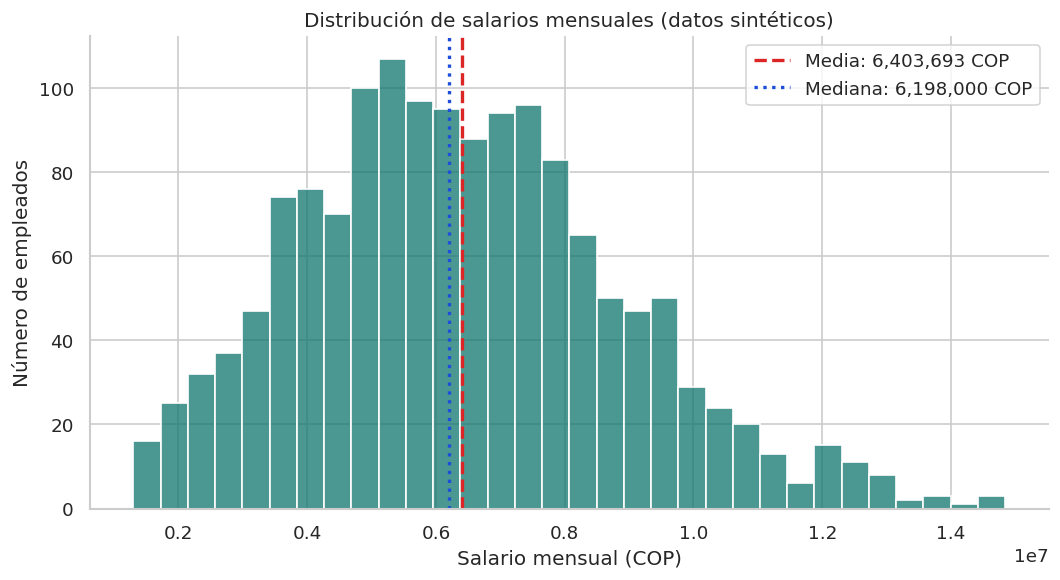

In [5]:
fig,ax=plt.subplots()
sns.histplot(data=df,x='SalarioMensualCOP',bins=32,color='#0f766e',ax=ax)
media=df['SalarioMensualCOP'].mean();mediana=df['SalarioMensualCOP'].median()
ax.axvline(media,color='#dc2626',linestyle='--',linewidth=2,label=f'Media: {media:,.0f} COP')
ax.axvline(mediana,color='#1d4ed8',linestyle=':',linewidth=2,label=f'Mediana: {mediana:,.0f} COP')
ax.set(title='Distribución de salarios mensuales (datos sintéticos)',xlabel='Salario mensual (COP)',ylabel='Número de empleados');ax.legend()
fig.tight_layout();fig.savefig(GRAF/'01_distribucion_salarios.png',dpi=180);plt.show()

## 5. Comparación: departamentos y niveles de cargo
El promedio por departamento puede reflejar diferencias de composición de cargos; **no prueba** que pertenecer a un departamento cause un salario mayor. Por ello contrastamos con nivel de cargo y experiencia.

,Departamento,Empleados,PromedioCOP,MedianaCOP
5,Tecnología,467,6840229.0,6772000.0
2,No reportado,11,6824818.0,6864000.0
1,Finanzas,216,6461310.0,6397500.0
0,Comercial,219,6364872.0,5930000.0
3,Operaciones,416,6060154.0,5888000.0
4,Talento Humano,155,5955135.0,5638000.0


,NivelCargo,Empleados,PromedioCOP,MedianaCOP
0,1,273,4421377.0,4360000.0
1,2,497,5442042.0,5354000.0
2,3,410,6759768.0,6823500.0
3,4,226,8507743.0,8479000.0
4,5,78,11501205.0,11785500.0


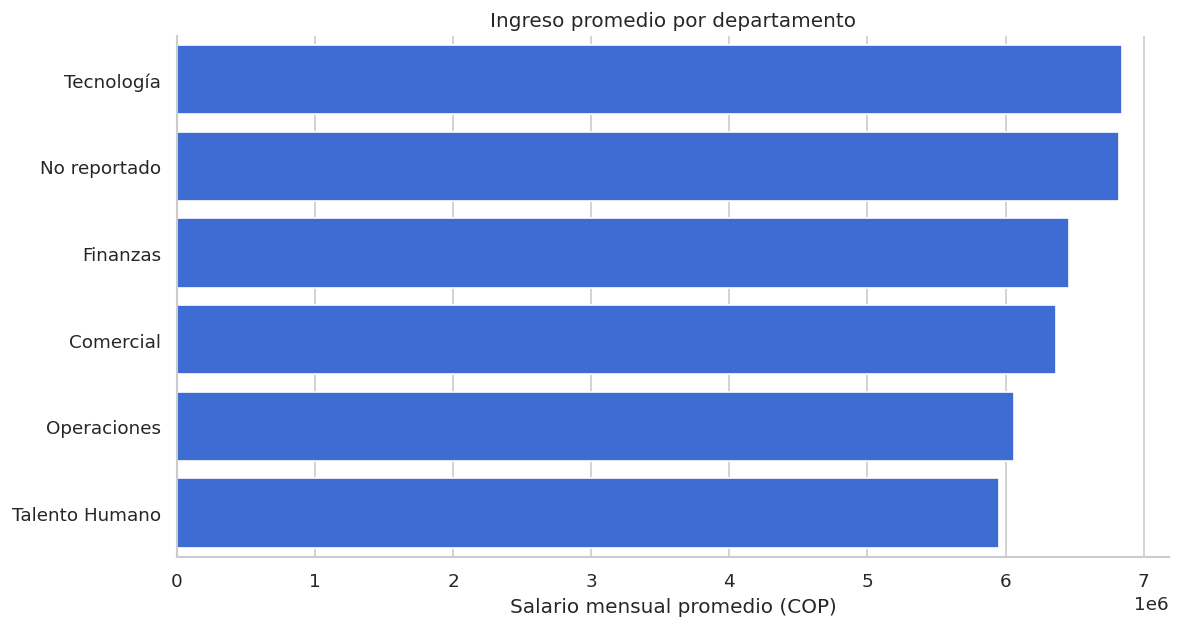

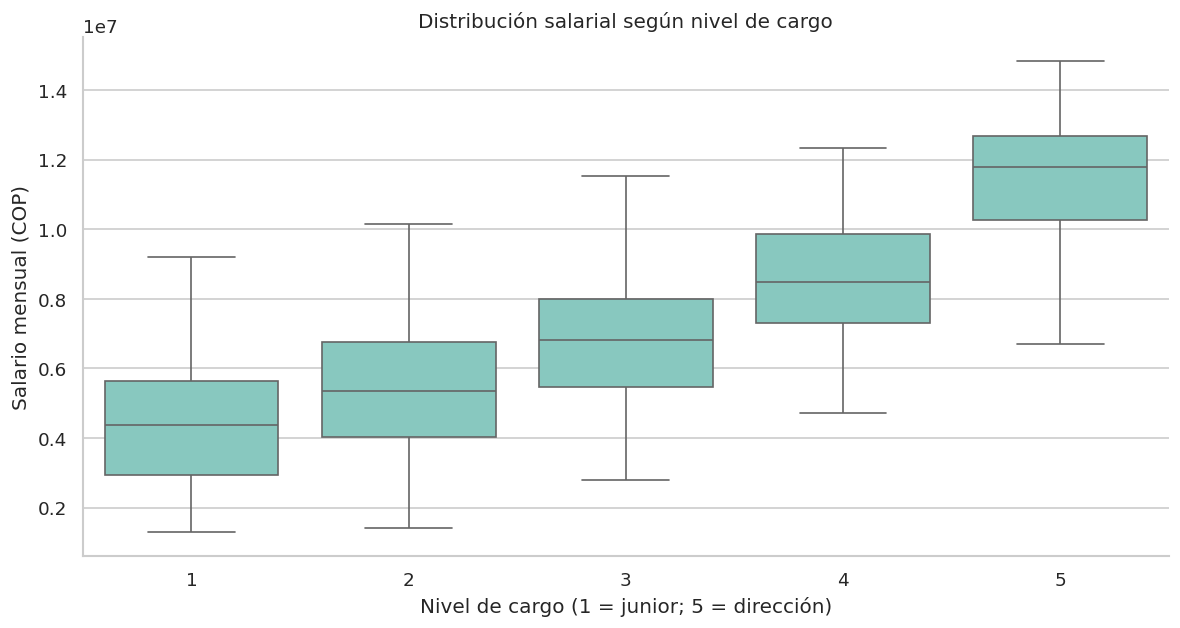

In [6]:
por_depto=df.groupby('Departamento',as_index=False).agg(
    Empleados=('EmpleadoID','count'),PromedioCOP=('SalarioMensualCOP','mean'),MedianaCOP=('SalarioMensualCOP','median'))
por_depto=por_depto.sort_values('PromedioCOP',ascending=False)
por_nivel=df.groupby('NivelCargo').agg(Empleados=('EmpleadoID','count'),PromedioCOP=('SalarioMensualCOP','mean'),MedianaCOP=('SalarioMensualCOP','median')).reset_index()
display(por_depto.round(0));display(por_nivel.round(0))
por_depto.to_csv(OUT/'resumen_departamentos.csv',index=False,encoding='utf-8-sig')
por_nivel.to_csv(OUT/'resumen_niveles.csv',index=False,encoding='utf-8-sig')
fig,ax=plt.subplots(figsize=(10,5.4));sns.barplot(data=por_depto,x='PromedioCOP',y='Departamento',color='#2563eb',ax=ax)
ax.set(title='Ingreso promedio por departamento',xlabel='Salario mensual promedio (COP)',ylabel='')
fig.tight_layout();fig.savefig(GRAF/'02_salario_por_departamento.png',dpi=180);plt.show()
fig,ax=plt.subplots(figsize=(10,5.4));sns.boxplot(data=df,x='NivelCargo',y='SalarioMensualCOP',color='#7dd3c7',showfliers=True,ax=ax)
ax.set(title='Distribución salarial según nivel de cargo',xlabel='Nivel de cargo (1 = junior; 5 = dirección)',ylabel='Salario mensual (COP)')
fig.tight_layout();fig.savefig(GRAF/'03_boxplot_nivel_cargo.png',dpi=180);plt.show()

## 6. Relaciones, valores atípicos e hipótesis

- Calculamos correlaciones de Pearson entre características numéricas. No inferimos causalidad.
- Definimos valores atípicos salariales con regla de IQR: menor que Q1 − 1.5×IQR o mayor que Q3 + 1.5×IQR. **Los marcamos pero no los eliminamos**, pues pueden ser salarios altos legítimos.
- **Hipótesis exploratoria:** en este escenario sintético, mayor nivel y experiencia estarán asociados con salarios mayores. El modelo predictivo servirá para evaluar si esa relación permite anticipar valores en datos no vistos.

IQR: 3,329,750 COP | límites: -343,125 a 12,975,875 COP | outliers marcados: 12


,SalarioMensualCOP,NivelCargo,ExperienciaAnios,AntiguedadAnios,Edad,HorasExtraMes
SalarioMensualCOP,1.000,0.695,0.584,0.326,0.543,0.007
NivelCargo,0.695,1.000,0.009,-0.002,-0.007,-0.009
ExperienciaAnios,0.584,0.009,1.000,0.484,0.934,-0.011
AntiguedadAnios,0.326,-0.002,0.484,1.000,0.483,-0.021
Edad,0.543,-0.007,0.934,0.483,1.000,-0.011
HorasExtraMes,0.007,-0.009,-0.011,-0.021,-0.011,1.000


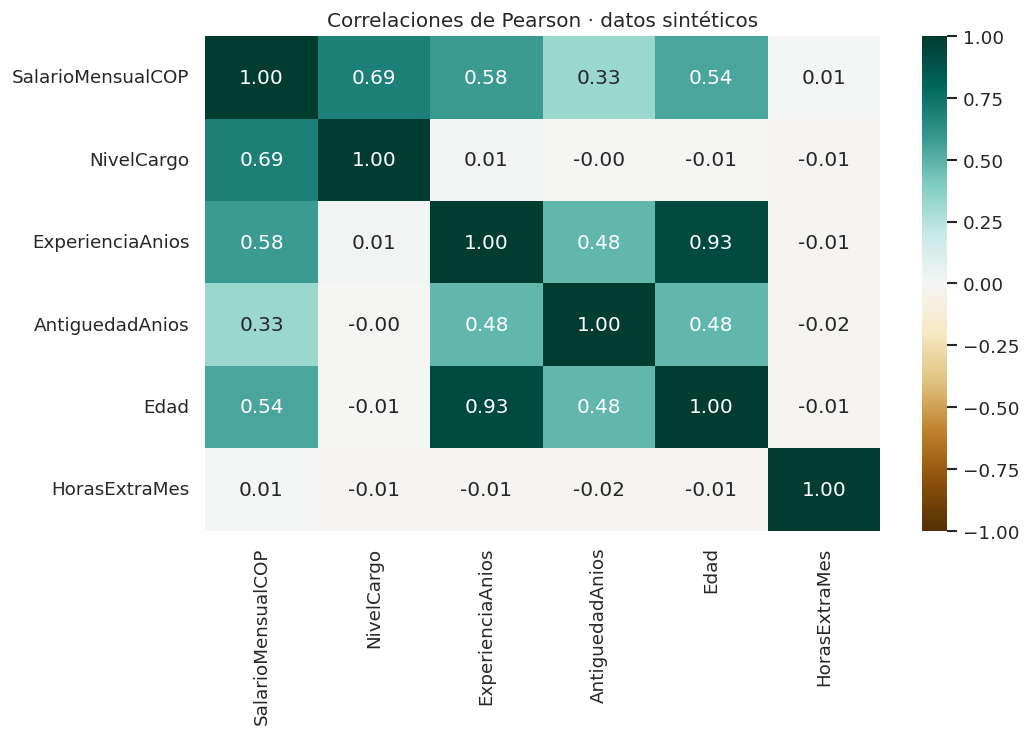

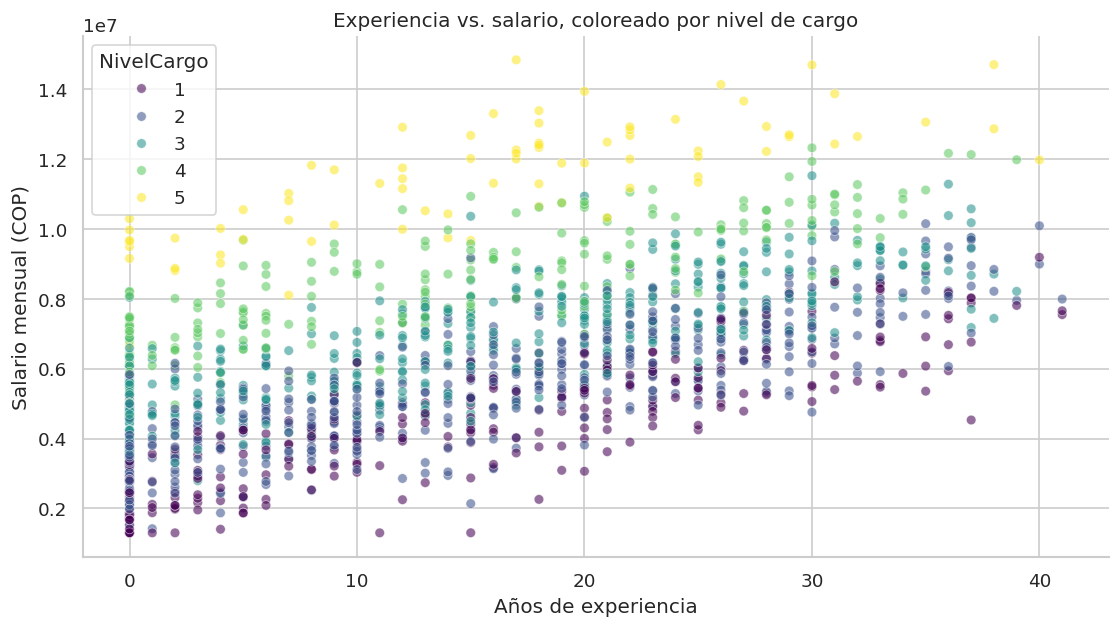

In [7]:
q1,q3=df['SalarioMensualCOP'].quantile([.25,.75]);iqr=q3-q1
inf,sup=q1-1.5*iqr,q3+1.5*iqr
n_out=int((~df['SalarioMensualCOP'].between(inf,sup)).sum())
print(f'IQR: {iqr:,.0f} COP | límites: {inf:,.0f} a {sup:,.0f} COP | outliers marcados: {n_out}')
cor=df[['SalarioMensualCOP','NivelCargo','ExperienciaAnios','AntiguedadAnios','Edad','HorasExtraMes']].corr()
display(cor.round(3))
fig,ax=plt.subplots(figsize=(9,6.3))
sns.heatmap(cor,annot=True,fmt='.2f',cmap='BrBG',center=0,vmin=-1,vmax=1,ax=ax)
ax.set(title='Correlaciones de Pearson · datos sintéticos')
fig.tight_layout();fig.savefig(GRAF/'04_matriz_correlaciones.png',dpi=180);plt.show()
fig,ax=plt.subplots(figsize=(9.5,5.4))
sns.scatterplot(data=df,x='ExperienciaAnios',y='SalarioMensualCOP',hue='NivelCargo',palette='viridis',alpha=.57,s=33,ax=ax)
ax.set(title='Experiencia vs. salario, coloreado por nivel de cargo',xlabel='Años de experiencia',ylabel='Salario mensual (COP)')
fig.tight_layout();fig.savefig(GRAF/'05_experiencia_vs_salario.png',dpi=180);plt.show()

# ETAPA 3 · Modelo matemático y storytelling

## 7. Preparación y prevención de fuga de datos

**Objetivo:** estimar `SalarioMensualCOP` con regresión lineal. Usaremos nivel de cargo, experiencia, antigüedad, departamento, formación, ciudad, modalidad y horas extra. Se excluyen el ID, la edad y satisfacción laboral del modelo: el ID no generaliza; evitamos incorporar variables personales o poco justificadas como predictores salariales.

**Diseño de evaluación:** partición 80% entrenamiento / 20% prueba con semilla 42. Las categorías se codifican con One Hot Encoding y las ausencias se imputan dentro del pipeline. Para evaluar valor añadido, también probamos una predicción base que siempre devuelve la mediana del entrenamiento.

In [8]:
NUM=['NivelCargo','ExperienciaAnios','AntiguedadAnios','HorasExtraMes']
CAT=['Departamento','NivelEducativo','Ciudad','ModalidadTrabajo']
X=model_inputs[NUM+CAT]; y=df['SalarioMensualCOP']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=42)
pre=ColumnTransformer([
    ('num',SimpleImputer(strategy='median'),NUM),
    ('cat',Pipeline([('imputar',SimpleImputer(strategy='most_frequent')),
                     ('onehot',OneHotEncoder(handle_unknown='ignore'))]),CAT)
])
modelo=Pipeline([('preprocesar',pre),('regresion',LinearRegression())])
base=DummyRegressor(strategy='median')
base.fit(X_train,y_train)
modelo.fit(X_train,y_train)
pred=modelo.predict(X_test); pred_base=base.predict(X_test)
def medir(real,estimado):
    return {'MAE_COP':float(mean_absolute_error(real,estimado)),
            'RMSE_COP':float(np.sqrt(mean_squared_error(real,estimado))),
            'R2':float(r2_score(real,estimado))}
met=medir(y_test,pred);mbase=medir(y_test,pred_base)
comp=pd.DataFrame([{'Modelo':'Base: mediana',**mbase},{'Modelo':'Regresión lineal',**met}])
display(comp.round(3))
print('Entrenamiento:',len(y_train),'| Prueba:',len(y_test))
assert met['MAE_COP'] < mbase['MAE_COP'], 'El modelo no supera la línea base'

,Modelo,MAE_COP,RMSE_COP,R2
0,Base: mediana,2059363.636,2578545.815,-0.000
1,Regresión lineal,764627.865,963012.456,0.861


Entrenamiento: 1187 | Prueba: 297


## 8. Validación cruzada y análisis del error

Para evitar confiar únicamente en una partición, hacemos validación cruzada de 5 pliegues sobre el **conjunto de entrenamiento**. MAE es el error absoluto promedio en COP, RMSE penaliza más errores altos y R² describe la fracción de variación explicada en la muestra de prueba (no es porcentaje de precisión).

R² de validación cruzada: 0.841 | MAE de validación cruzada: 764,528 COP


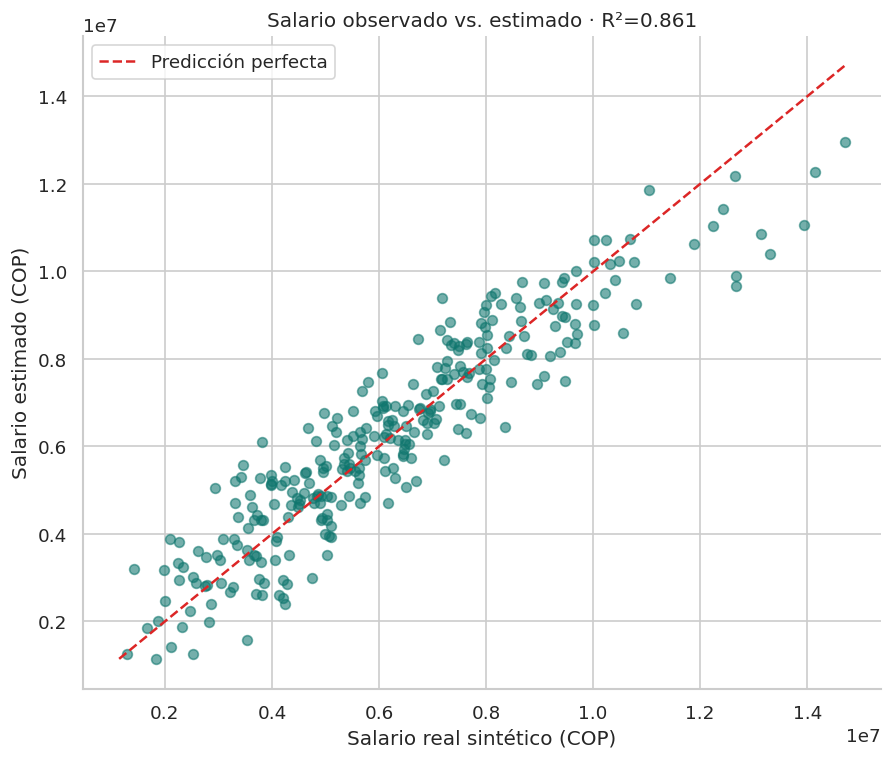

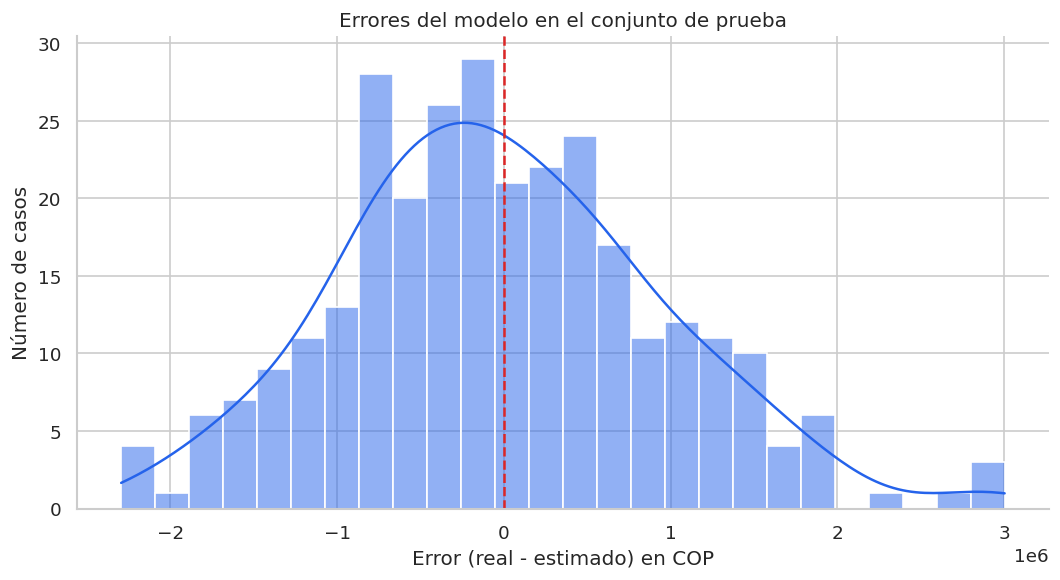

In [9]:
cv=KFold(n_splits=5,shuffle=True,random_state=42)
cruzada=cross_validate(modelo,X_train,y_train,cv=cv,scoring={'r2':'r2','mae':'neg_mean_absolute_error'},n_jobs=1)
cv_r2=float(np.mean(cruzada['test_r2'])); cv_mae=float(-np.mean(cruzada['test_mae']))
print(f'R² de validación cruzada: {cv_r2:.3f} | MAE de validación cruzada: {cv_mae:,.0f} COP')
fig,ax=plt.subplots(figsize=(7.6,6.5))
ax.scatter(y_test,pred,alpha=.58,s=34,color='#0f766e')
lim=[min(y_test.min(),pred.min()),max(y_test.max(),pred.max())]
ax.plot(lim,lim,color='#dc2626',linestyle='--',label='Predicción perfecta')
ax.set(title=f'Salario observado vs. estimado · R²={met["R2"]:.3f}',xlabel='Salario real sintético (COP)',ylabel='Salario estimado (COP)');ax.legend()
fig.tight_layout();fig.savefig(GRAF/'06_real_vs_predicho.png',dpi=180);plt.show()
fig,ax=plt.subplots(figsize=(9,5.0))
sns.histplot(y_test-pred,kde=True,bins=26,color='#2563eb',ax=ax)
ax.axvline(0,color='#dc2626',linestyle='--')
ax.set(title='Errores del modelo en el conjunto de prueba',xlabel='Error (real - estimado) en COP',ylabel='Número de casos')
fig.tight_layout();fig.savefig(GRAF/'07_residuos.png',dpi=180);plt.show()

## 9. Interpretación sencilla y cautelas

Una predicción tiene **incertidumbre**: el error MAE indica cuánto se alejan, en promedio, los valores estimados del salario simulado verdadero. No se debe usar para asignar sueldos reales a personas, ni para decidir ascensos o remuneraciones sin auditoría, representatividad, transparencia y control humano.

El sistema solo aprende reglas presentes en el generador artificial. Por diseño puede rendir bien en este ejercicio; ese rendimiento **no demuestra** que funcionará igual en empresas colombianas.

In [10]:
coef=pd.Series(modelo.named_steps['regresion'].coef_,
               index=modelo.named_steps['preprocesar'].get_feature_names_out()).sort_values(key=abs,ascending=False)
print('Coeficientes de mayor magnitud (asociaciones del modelo, no efectos causales):')
display(coef.head(12).round(0).to_frame('Coeficiente_estimado_COP'))
resumen={
  'origen':'Datos sintéticos con semilla 202611: no son registros reales',
  'n_original':int(len(df_raw)),'duplicados_eliminados':int(antes_dup),
  'registros_descartados':int(antes_err),'n_depurado':int(len(df)),
  'salario_promedio_cop':round(float(media),2), 'salario_mediano_cop':round(float(mediana),2),
  'salario_desviacion_estandar_cop':round(float(df['SalarioMensualCOP'].std()),2),
  'n_outliers_iqr':n_out, 'correlacion_nivel_salario':round(float(cor.loc['NivelCargo','SalarioMensualCOP']),4),
  'correlacion_experiencia_salario':round(float(cor.loc['ExperienciaAnios','SalarioMensualCOP']),4),
  'n_entrenamiento':int(len(y_train)),'n_prueba':int(len(y_test)),
  'baseline':{x:round(v,4) for x,v in mbase.items()},
  'regresion':{x:round(v,4) for x,v in met.items()},
  'validacion_cruzada_r2_promedio':round(cv_r2,4),'validacion_cruzada_mae_cop_promedio':round(cv_mae,2),
  'departamento_mayor_promedio':str(por_depto.iloc[0]['Departamento']),
  'nivel_modal':int(df['NivelCargo'].mode().iat[0])}
(OUT/'metricas_modelo.json').write_text(json.dumps(resumen,ensure_ascii=False,indent=2),encoding='utf-8')
pd.DataFrame({'SalarioRealCOP':y_test,'SalarioPredichoCOP':pred,'ErrorCOP':y_test-pred}).to_csv(OUT/'predicciones_prueba.csv',index=False,encoding='utf-8-sig')
print(json.dumps(resumen,ensure_ascii=False,indent=2))

Coeficientes de mayor magnitud (asociaciones del modelo, no efectos causales):


,Coeficiente_estimado_COP
num__NivelCargo,1509453.0
cat__NivelEducativo_Maestría,589916.0
cat__Departamento_Tecnología,564439.0
cat__Departamento_No reportado,-523951.0
cat__NivelEducativo_Bachillerato,-382596.0
cat__NivelEducativo_Especialización,328732.0
cat__Departamento_Finanzas,297913.0
cat__Departamento_Operaciones,-293896.0
cat__Departamento_Talento Humano,-265250.0
cat__NivelEducativo_No reportado,-257338.0


{
  "origen": "Datos sintéticos con semilla 202611: no son registros reales",
  "n_original": 1514,
  "duplicados_eliminados": 14,
  "registros_descartados": 16,
  "n_depurado": 1484,
  "salario_promedio_cop": 6403692.72,
  "salario_mediano_cop": 6198000.0,
  "salario_desviacion_estandar_cop": 2471448.81,
  "n_outliers_iqr": 12,
  "correlacion_nivel_salario": 0.6948,
  "correlacion_experiencia_salario": 0.584,
  "n_entrenamiento": 1187,
  "n_prueba": 297,
  "baseline": {
    "MAE_COP": 2059363.6364,
    "RMSE_COP": 2578545.8154,
    "R2": -0.0
  },
  "regresion": {
    "MAE_COP": 764627.8654,
    "RMSE_COP": 963012.4557,
    "R2": 0.8605
  },
  "validacion_cruzada_r2_promedio": 0.8409,
  "validacion_cruzada_mae_cop_promedio": 764527.55,
  "departamento_mayor_promedio": "Tecnología",
  "nivel_modal": 2
}


## 10. Storytelling y aplicación profesional

**Problema:** una dirección de Talento Humano quiere entender por qué los ingresos varían entre colaboradores y cómo construir una estimación inicial del presupuesto de personal.

**Evidencia:** comenzamos con la distribución salarial y su dispersión; luego desagregamos por departamento y nivel de cargo; finalmente evaluamos un modelo contra una predicción ingenua y medimos sus errores sobre casos nunca vistos.

**Interpretación:** si el modelo supera al baseline, las características laborales sintéticas aportan información predictiva. El resultado debe leerse con cuidado: correlación no equivale a causa y un dato ficticio no es base para política salarial.

**Aplicación profesional propuesta:** como ingenieros de sistemas, desarrollaríamos un prototipo de tablero de nómina y control de calidad que integre datos autorizados desde SAP HCM, aplique validaciones de calidad y genere estimaciones **agregadas** de presupuesto. En la vida real requeriríamos anonimización, permisos, validación con HR y revisión de sesgos antes del despliegue.

### Conclusión y aprendizaje
Se completaron las tres fases: limpiar, describir y comunicar con un modelo explicable y evaluado. La lección principal es que un gráfico o predicción solo es útil si conocemos **origen, calidad, límites y contexto** de los datos.

In [11]:
print('RESUMEN PARA LA PRESENTACIÓN')
print(f'- Datos: {len(df_raw):,} registros originales → {len(df):,} depurados.')
print(f'- Salario medio: {media:,.0f} COP; mediana: {mediana:,.0f} COP.')
print(f'- Correlación nivel–salario: {cor.loc["NivelCargo","SalarioMensualCOP"]:.2f}.')
print(f'- Baseline MAE: {mbase["MAE_COP"]:,.0f} COP | Regresión MAE: {met["MAE_COP"]:,.0f} COP.')
print(f'- R² prueba: {met["R2"]:.3f} | R² validación cruzada: {cv_r2:.3f}.')
print(f'- Outliers IQR conservados: {n_out}.')

RESUMEN PARA LA PRESENTACIÓN
- Datos: 1,514 registros originales → 1,484 depurados.
- Salario medio: 6,403,693 COP; mediana: 6,198,000 COP.
- Correlación nivel–salario: 0.69.
- Baseline MAE: 2,059,364 COP | Regresión MAE: 764,628 COP.
- R² prueba: 0.861 | R² validación cruzada: 0.841.
- Outliers IQR conservados: 12.
